# La foto: presión sobre el mercado laboral en Gran Córdoba, 1er trimestre 2026

Este análisis nace de una inquietud que me plantearon varias personas de distintos ámbitos de la ciudad de Córdoba. La pregunta era siempre la misma: ¿qué está pasando en el mercado laboral? Mil postulaciones para una sola vacante. Por eso decidí mirar los datos, para tener un panorama más claro y que quien está buscando trabajo entienda que no es solo su CV.

**Fuente:** EPH-INDEC, base individual, 1er trimestre de 2026. Ponderado con `PONDERA`.

**Indicador:** presión = (desocupados + ocupados que buscan otro empleo) / PEA.

## 1. Datos

Uso la base individual de la EPH del primer trimestre de 2026, que se descarga desde la página de bases de datos del INDEC (https://www.indec.gob.ar/Institucional/Indec/BasesDeDatos). Para correr el notebook hay que descomprimirla dentro de una carpeta `datos/`, al lado de este archivo.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ruta = next(Path("datos").rglob("usu_individual_*126*.txt"))   # base del 1er trimestre 2026
eph = pd.read_csv(ruta, sep=";", decimal=",", encoding="latin-1", low_memory=False)
eph.shape

(43739, 234)

In [2]:
cordoba = eph[eph["AGLOMERADO"] == 13]
bases = {"Total aglomerados": eph, "Gran Córdoba": cordoba}

pd.Series({nombre: len(b[b["ESTADO"].isin([1, 2])]) for nombre, b in bases.items()},
          name="PEA encuestada (casos)")

Total aglomerados    20996
Gran Córdoba          1017
Name: PEA encuestada (casos), dtype: int64

El aglomerado de Gran Córdoba tiene 1.017 casos. Son las personas activas (que trabajan o buscan trabajo) que respondieron la encuesta. Es una de las muestras más grandes del interior del país, por eso se puede analizar sola. Igual tiene un margen de error de unos ±4 puntos, así que las diferencias chicas hay que tomarlas con cuidado.

## 2. Tasas básicas y validación contra el INDEC

In [3]:
def tasas(d):
    poblacion = d["PONDERA"].sum()
    ocupados = d.loc[d["ESTADO"] == 1, "PONDERA"].sum()
    desocupados = d.loc[d["ESTADO"] == 2, "PONDERA"].sum()
    pea = ocupados + desocupados
    return pd.Series({"Actividad (%)": pea / poblacion * 100,
                      "Empleo (%)": ocupados / poblacion * 100,
                      "Desocupación (%)": desocupados / pea * 100})

pd.DataFrame({nombre: tasas(b) for nombre, b in bases.items()}).round(1)

,Total aglomerados,Gran Córdoba
Actividad (%),48.6,52.1
Empleo (%),44.8,47.6
Desocupación (%),7.8,8.8


Antes de seguir con el análisis, comparé estas tasas con las que publica el INDEC en su informe de mercado de trabajo del primer trimestre de 2026. Coinciden (por ejemplo, la desocupación da 7,8% en los dos casos), lo que confirma que la base está bien procesada y que los resultados que siguen son confiables.

## 3. Presión sobre el mercado laboral

La desocupación solo cuenta a quienes no tienen trabajo y lo están buscando. Pero quien se postula a un aviso compite también con personas que ya trabajan y buscan otro empleo. Por eso miro la presión sobre el mercado laboral: suma desocupados y ocupados que buscan otro empleo, sobre el total de personas en el mercado laboral (PEA).

El INDEC publica un indicador de presión más amplio, que además incluye a quienes trabajan y estarían disponibles para trabajar más aunque no estén buscando. Acá uso solo la parte activa: las personas que efectivamente salieron a buscar.

In [4]:
def presion(d):
    pea_casos = d[d["ESTADO"].isin([1, 2])]
    pea = pea_casos["PONDERA"].sum()
    desocupados = d.loc[d["ESTADO"] == 2, "PONDERA"].sum()
    buscan = d.loc[(d["ESTADO"] == 1) & (d["PP03J"] == 1), "PONDERA"].sum()
    p = (desocupados + buscan) / pea
    n = len(pea_casos)
    return pd.Series({
        "Desocupados (% PEA)": desocupados / pea * 100,
        "Buscan otro empleo (% PEA)": buscan / pea * 100,
        "Presión (%)": p * 100,
        "n (PEA)": n,
        # margen al 95%, con efecto de diseño de 1,3 por ser una muestra por conglomerados
        "Margen ± (pp)": 1.96 * np.sqrt(p * (1 - p) / n) * 1.3 * 100,
    })

pd.DataFrame({nombre: presion(b) for nombre, b in bases.items()}).round(1)

,Total aglomerados,Gran Córdoba
Desocupados (% PEA),7.8,8.8
Buscan otro empleo (% PEA),15.8,30.2
Presión (%),23.7,39.0
n (PEA),20996.0,1017.0
Margen ± (pp),0.7,3.9


En Gran Córdoba, 39 de cada 100 personas en el mercado laboral están buscando empleo. En el total de los aglomerados son 24. La diferencia casi no viene de la desocupación, que es parecida (8,8% contra 7,8%). Viene de las personas que ya trabajan y buscan otro empleo: 30 de cada 100 en Córdoba, contra 16 en el total.

### 3.1 Ranking de aglomerados

In [5]:
nombres_aglo = {
    2: "Gran La Plata", 3: "Bahía Blanca-Cerri", 4: "Gran Rosario", 5: "Gran Santa Fe",
    6: "Gran Paraná", 7: "Posadas", 8: "Gran Resistencia", 9: "Comodoro Rivadavia-Rada Tilly",
    10: "Gran Mendoza", 12: "Corrientes", 13: "Gran Córdoba", 14: "Concordia",
    15: "Formosa", 17: "Neuquén-Plottier", 18: "Santiago del Estero-La Banda", 19: "Jujuy-Palpalá",
    20: "Río Gallegos", 22: "Gran Catamarca", 23: "Gran Salta", 25: "La Rioja",
    26: "Gran San Luis", 27: "Gran San Juan", 29: "Gran Tucumán-Tafí Viejo", 30: "Santa Rosa-Toay",
    31: "Ushuaia-Río Grande", 32: "CABA", 33: "Partidos del GBA", 34: "Mar del Plata",
    36: "Río Cuarto", 38: "San Nicolás-Villa Constitución", 91: "Rawson-Trelew",
    93: "Viedma-Carmen de Patagones",
}

ranking = (eph.groupby("AGLOMERADO")[["ESTADO", "PP03J", "PONDERA"]].apply(presion)
              [["Presión (%)", "Margen ± (pp)", "n (PEA)"]])
ranking.index = ranking.index.map(nombres_aglo)
ranking = ranking.sort_values("Presión (%)", ascending=False).round(1)
ranking.head(10)

,Presión (%),Margen ± (pp),n (PEA)
AGLOMERADO,,,
Gran Córdoba,39.0,3.9,1017.0
Gran Tucumán-Tafí Viejo,34.8,3.8,1038.0
Gran La Plata,31.7,6.0,387.0
Gran Mendoza,29.7,3.9,892.0
Santa Rosa-Toay,27.5,5.2,472.0
Gran Catamarca,27.4,4.4,657.0
Gran San Juan,26.4,4.8,558.0
Partidos del GBA,25.5,2.1,2756.0
Rawson-Trelew,24.0,5.9,341.0


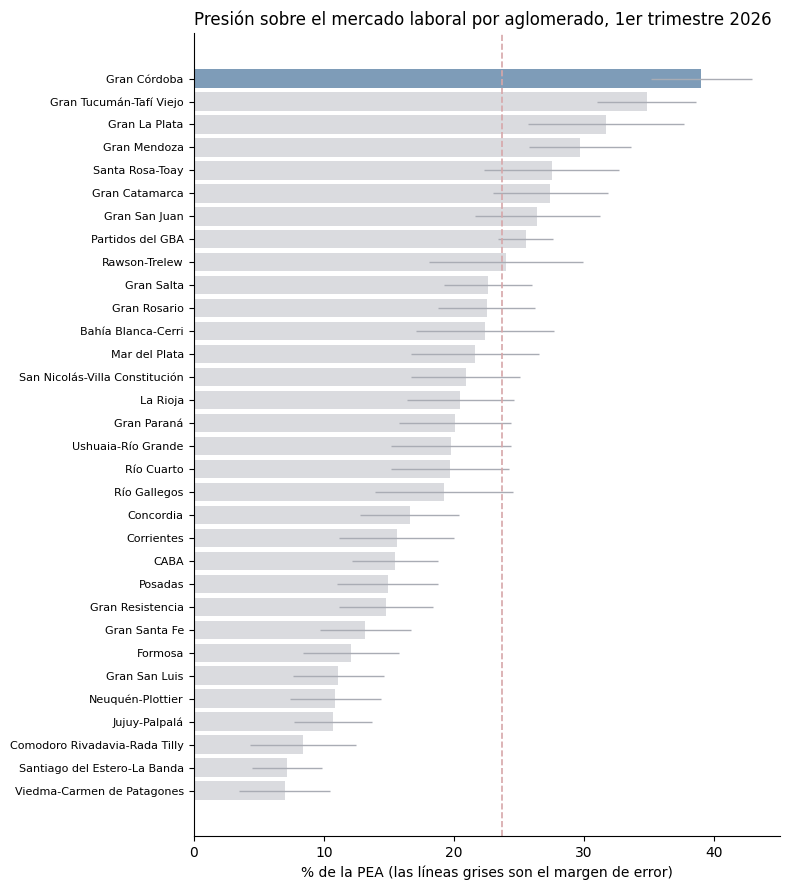

In [6]:
fig, ax = plt.subplots(figsize=(8, 9))
orden = ranking.sort_values("Presión (%)")
colores = ["#7E9CB8" if a == "Gran Córdoba" else "#DADBDF" for a in orden.index]
ax.barh(orden.index, orden["Presión (%)"], xerr=orden["Margen ± (pp)"],
        color=colores, error_kw={"ecolor": "#A9ACB4", "lw": 1})
ax.axvline(presion(eph)["Presión (%)"], color="#D7A7A9", linestyle="--", linewidth=1.2)
ax.set_title("Presión sobre el mercado laboral por aglomerado, 1er trimestre 2026", loc="left")
ax.set_xlabel("% de la PEA (las líneas grises son el margen de error)")
ax.tick_params(axis="y", labelsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Gran Córdoba tiene el valor más alto de todos los aglomerados. Pero con el margen de error queda empatada con Gran Tucumán (39,0 contra 34,8), así que lo correcto es decir que está entre los aglomerados con más presión del país, no que es el primero.

## 4. ¿Para qué buscan otro empleo los que ya trabajan?

Esta pregunta (PP03K) existe desde 2024, cuando el INDEC actualizó el cuestionario. Por eso este dato muestra solo la situación actual y no se puede comparar con años anteriores.

In [7]:
motivos = {1: "Quiere cambiar de trabajo", 2: "Quiere sumar otro trabajo",
           3: "Se le termina el trabajo que tiene", 4: "Estaba sin trabajo"}

def para_que_buscan(d):
    buscan = d[(d["ESTADO"] == 1) & (d["PP03J"] == 1)]
    total = buscan["PONDERA"].sum()
    r = {texto: buscan.loc[buscan["PP03K"] == cod, "PONDERA"].sum() / total * 100
         for cod, texto in motivos.items()}
    r["Casos en la muestra"] = len(buscan)
    return pd.Series(r)

pd.DataFrame({nombre: para_que_buscan(b) for nombre, b in bases.items()}).round(1)

,Total aglomerados,Gran Córdoba
Quiere cambiar de trabajo,39.8,35.5
Quiere sumar otro trabajo,56.3,60.5
Se le termina el trabajo que tiene,2.2,3.1
Estaba sin trabajo,1.7,0.9
Casos en la muestra,3155.0,302.0


En Gran Córdoba, 6 de cada 10 personas que trabajan y buscan otro empleo quieren sumar un trabajo, no cambiar el que tienen. En el total de los aglomerados son 56 de cada 100. Lo leo como una señal de que, para muchos, un solo ingreso no alcanza. El dato sale de 302 casos, así que tiene un margen de unos ±7 puntos.

## 5. ¿Por qué no encuentran trabajo los desocupados?

A las personas desocupadas la EPH les pregunta por qué creen que no consiguen trabajo. Pueden marcar más de una razón, por eso los porcentajes no suman 100.

In [8]:
razones = {
    "PP10B1": "Recién empezó a buscar",
    "PP10B2": "Por la edad",
    "PP10B3": "Falta de trabajo en su especialidad",
    "PP10B4": "No tiene experiencia o capacitación",
    "PP10B5": "Le faltan contactos",
    "PP10B6": "No hay trabajo",
    "PP10B7": "No le alcanza la plata para salir a buscar",
    "PP10B8": "Suspendido",
    "PP10B9": "Otras razones",
    "PP10B10": "Desconoce por qué no encuentra",
}

def razones_no_encuentra(d):
    desoc = d[d["ESTADO"] == 2]
    total = desoc["PONDERA"].sum()
    r = {texto: desoc.loc[desoc[var] == 1, "PONDERA"].sum() / total * 100
         for var, texto in razones.items()}
    r["Casos en la muestra"] = len(desoc)
    return pd.Series(r)

tabla_razones = pd.DataFrame({nombre: razones_no_encuentra(b) for nombre, b in bases.items()}).round(1)
tabla_razones

,Total aglomerados,Gran Córdoba
Recién empezó a buscar,24.8,23.9
Por la edad,36.7,34.7
Falta de trabajo en su especialidad,31.5,24.5
No tiene experiencia o capacitación,28.0,22.0
Le faltan contactos,52.5,45.5
No hay trabajo,68.2,64.8
No le alcanza la plata para salir a buscar,13.7,14.5
Suspendido,0.7,2.9
Otras razones,9.4,11.1
Desconoce por qué no encuentra,0.6,0.0


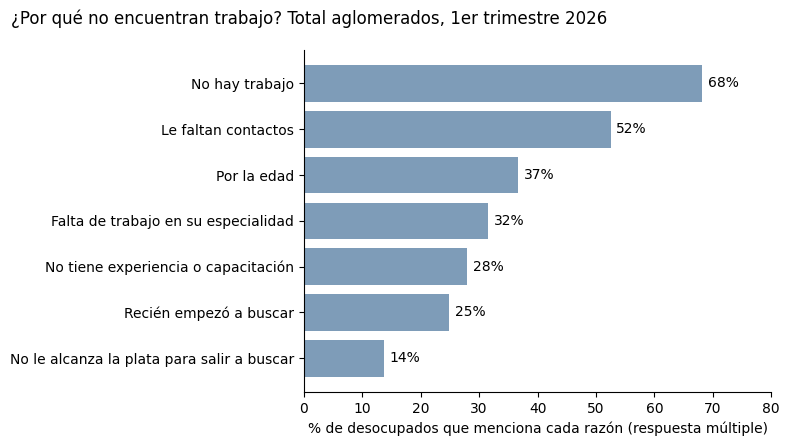

In [9]:
datos = (tabla_razones["Total aglomerados"]
         .drop(["Casos en la muestra", "Suspendido", "Otras razones", "Desconoce por qué no encuentra"])
         .sort_values())

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(datos.index, datos, color="#7E9CB8")
for i, v in enumerate(datos):
    ax.text(v + 1, i, f"{v:.0f}%", va="center", fontsize=10)
ax.set_xlim(0, 80)
fig.suptitle("¿Por qué no encuentran trabajo? Total aglomerados, 1er trimestre 2026", x=0.02, ha="left")
ax.set_xlabel("% de desocupados que menciona cada razón (respuesta múltiple)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

La razón más mencionada es que no hay trabajo: 68 de cada 100 desocupados la marcan. La segunda es la falta de contactos: 52 de cada 100. Para mí es el dato más fuerte, porque muestra que conseguir trabajo depende mucho de la red de cada uno y no solo del CV. En Gran Córdoba los valores son parecidos (65 y 46), pero con solo 98 desocupados en la muestra el margen de error es muy grande para compararlos.

## 6. Informalidad

Para la informalidad uso la variable oficial del INDEC (EMPLEO), que también existe desde 2024. Considera informales a los asalariados sin aportes jubilatorios, a los trabajadores familiares sin remuneración y a quienes trabajan por su cuenta o son patrones sin cumplir sus obligaciones tributarias y previsionales.

In [10]:
def informalidad(d):
    ocup = d[(d["ESTADO"] == 1) & (d["EMPLEO"].isin([1, 2]))]
    return pd.Series({
        "Informalidad (% de ocupados)": ocup.loc[ocup["EMPLEO"] == 2, "PONDERA"].sum() / ocup["PONDERA"].sum() * 100,
        "Casos en la muestra": len(ocup),
    })

pd.DataFrame({nombre: informalidad(b) for nombre, b in bases.items()}).round(1)

,Total aglomerados,Gran Córdoba
Informalidad (% de ocupados),44.2,48.5
Casos en la muestra,19560.0,918.0


En Gran Córdoba, casi la mitad de las personas ocupadas (48,5%) trabaja en la informalidad. En el total de los aglomerados es el 44,2%.

## 7. Limitaciones

- Es una foto de un solo trimestre. Lo que pasó en el tiempo está en el notebook `02_la_pelicula`.
- La EPH es una encuesta por muestra: cada número tiene un margen de error, mayor cuanto más chico es el grupo.
- Las razones por las que no encuentran trabajo (sección 5) corresponden al total de los aglomerados y no a Gran Córdoba, porque en Córdoba hay solo 98 desocupados en la muestra, muy pocos para un resultado confiable.
- Las preguntas de motivos de búsqueda e informalidad existen recién desde 2024.
- Mi indicador de presión es la parte activa del que publica el INDEC, por eso da más bajo que el oficial.